# What does a predictor from R0 alone miss?

**Question:** Can the template's small regression predictor summarize the peak of every SIR scenario from its reproduction ratio alone, and how do training, held-out evaluation and omitted initial conditions change that interpretation?

- **Level:** 2, the method in practice
- **Prerequisites:** both preceding threshold and final-size lessons, plus the engine lesson
- **Reading time:** about 40 minutes

## Objectives

Follow an input from the actual admission and feature stages to a temporary trained model, then distinguish fitting error, held-out error and lost input information. The exercise concerns the existing four-term regression and its analytic fallback. It does not propose a new epidemic method, train a forecasting system or replace the released model. The central question is whether a convenient one-number interface retains enough information for the quantity a reader thinks it predicts.

## Setup

Use the exact notebook environment:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

This template publishes no Python method distribution. Import the existing `data-pipeline` modules by their repository path. Set `CAOS_TEMP_ROOT` to an external working directory before using the runner. The temporary-directory context below removes only the example model it owns; it never writes under canonical `models/`. The setup reads the committed schema. The Data cell selects the registry cases and loads the committed model without changing either.

In [1]:
# Keep temporary training outside the checkout and use the existing stage APIs.
import importlib.metadata as md
import json
import os
import sys
from dataclasses import replace
from pathlib import Path
from tempfile import TemporaryDirectory

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline import registry
from pipeline.io.schema import SIRParams
from pipeline.model.baseline import is_valid_bundle, peak_frac
from pipeline.stages import evaluate, feature_extraction, infer, preprocess, train

for name in ("numpy", "matplotlib"):
    print(name, md.version(name))
bundle_schema = json.loads((ROOT / "docs/contracts/schemas/surrogate-model.schema.json").read_text(encoding="utf-8"))


numpy 2.4.6
matplotlib 3.11.2


## Data

The owner is this repository, https://github.com/fsantibanezleal/CAOS_PRODUCT_TEMPLATE; its MIT licence covers the authored synthetic examples. There are no patient observations or clinical datasets. Read `data/examples/params.csv`, `data/derived/manifests/index.json`, `models/surrogate.json` and `docs/contracts/schemas/surrogate-model.schema.json`. Training operating points come through the public registry, whose case parameters define the same declared examples as the index. New held-out operating points are deterministic perturbations of the epidemic case, labelled separately rather than presented as field data.

The CSV intentionally includes invalid negative-contact and excessive-initial-infection rows. Running preprocessing first teaches the actual params-record boundary: beta/gamma are inverse days, N/I0 are people and days is a horizon. Its accepted feature rows expose r0, beta, gamma, logarithmic population and initial infected fraction. The fit will deliberately consume only r0.

In [2]:
# Admission must precede feature computation, including rejected source rows.
released = train.load_released(ROOT / "models")
training = [case.params for case in registry.list_cases() if case.params.I0 > 0]
base = registry.get_case("EX02_epidemic").params
admission = preprocess.run(str(ROOT / "data/examples/params.csv"))
features = feature_extraction.run(admission.accepted)
print(admission.summary())
for row in features:
    print(row.case_id, f"r0={row.r0:.2f}, log10(N)={row.n_scaled:.1f}, i0_frac={row.i0_frac:.5f}")
print("rejected:", [row["case_id"] for row in admission.rejected])

2 accepted, 2 rejected, 0 flagged
EX02_epidemic r0=2.75, log10(N)=5.0, i0_frac=0.00050
EX01_subcritical r0=0.72, log10(N)=5.0, i0_frac=0.00050
rejected: ['bad_negbeta', 'bad_i0_gt_N']


## Method

The feature stage retains more information than the model slot uses. Its `FeatureRow` contains the original rates, population scale and initial infected fraction, yet the trainer builds a design matrix from the scalar reproduction ratio. For row $j$, output $y_j$ is the engine's maximum infected count divided by its population over that row's requested horizon. The actual fitting problem is

$$\widetilde r=\max(r,10^{-6}),\quad\phi(r)=(1,\widetilde r,\ln\widetilde r,1/\widetilde r),\quad X_{j,:}=\phi(r_j),\quad c^*=\operatorname*{argmin}_c\|Xc-y\|_2^2.$$

All feature columns and targets are dimensionless; coefficient interpretation follows the exact declared column order. NumPy's primary least-squares API documents the residual-minimizing solution and rank convention. The four columns are the template author's small illustrative choice, not a learned scientific discovery or a basis proved optimal for epidemics. The existing trainer calls that API; this notebook never reconstructs its design routine or estimates coefficients independently.

The shipped orchestration trains on nondegenerate registry cases and evaluates on a separate seeded twenty-point synthetic draw. This lesson uses the same public trainer but a distinct six-point held-out grid so the distinction is visible. Its errors therefore do not reproduce or supersede the released manifest metrics. Excluding the exactly unseeded control from fitting is part of that source protocol; it also reveals an important limitation when the predictor is later asked about an unseeded population.

The actual design first uses max(r0,1e-6), so positive ratios below that cutoff receive identical features. The displayed formula now includes that exact computational domain. This floor is not input admission: the slot requires a finite positive reproduction ratio, and legacy helper behavior on unadmitted values is not a valid prediction.

In [3]:
# Train on declared cases while reserving genuinely different operating points.
train_r0 = [p.beta / p.gamma for p in training]
train_truth = [infer.run(p).peak_I / p.N for p in training]
held_r0 = [0.9, 1.5, 2.0, 3.5, 5.0, 7.0]
holdout = [replace(base, case_id=f"lesson_holdout_{k}", beta=r0 * base.gamma)
           for k, r0 in enumerate(held_r0)]
held_truth = [infer.run(p).peak_I / p.N for p in holdout]
print("training R0:", [round(v, 2) for v in train_r0])
print("held-out R0:", held_r0)
print("shared R0:", sorted(set(train_r0).intersection(held_r0)))

training R0: [0.72, 2.75, 6.0, 1.2]
held-out R0: [0.9, 1.5, 2.0, 3.5, 5.0, 7.0]
shared R0: []


The two printed reproduction-ratio lists have no shared value. That removes direct reuse of a training operating point, but does not make this a representative real-world test. Both sets still come from the same deterministic equations and share population, initial infection scale and largely similar horizons. There are four fitted coefficients and four training cases, so very small training residuals can reflect interpolation rather than generalization. The next cell uses the existing trainer in a temporary external directory, reads the bundle through the released-model loader, and displays its semantic fields. It also reads the canonical bundle without modifying it.

In [4]:
# A temporary bundle exercises the real trainer without touching the released model.
with TemporaryDirectory(prefix="sir-lesson-", dir=os.environ["CAOS_TEMP_ROOT"]) as temporary:
    model = train.run(training, temporary)
    loaded = train.load_released(temporary)
    print("valid bundle:", is_valid_bundle(loaded))
print("required fields:", bundle_schema["required"])
print("kind:", model["kind"], "basis:", model["basis"])
print("coeffs:", [round(value, 6) for value in model["coeffs"]])
print("released bundle valid:", is_valid_bundle(released))

valid bundle: True
required fields: ['kind', 'basis', 'coeffs']
kind: linear-lstsq basis: ['1', 'r0', 'ln(r0)', '1/r0']
coeffs: [-0.607253, -0.071256, 0.823704, 0.669346]
released bundle valid: True


The surrogate-model contract requires exactly `kind`, `basis` and `coeffs`. The kind is `linear-lstsq`; basis names and order must match the four fixed columns; coefficients must be four finite numbers. `is_valid_bundle` is the product's semantic predicate for that shape, including the rejection of extra fields and invalid numeric types. A valid bundle can still predict poorly: schema and semantic admission do not establish that the training data cover a new use case. Likewise the loader returning a model says only that a usable released bundle exists, not that a newer training job completed or that a prediction has statistical uncertainty attached.

At inference the public predictor evaluates the fitted expression and clamps it into the contractual fraction interval:

$$\widehat p(r)=\min(1,\max(0,\phi(r)^\top c^*)),\qquad \operatorname{RMSE}=\sqrt{\frac1m\sum_{j=1}^m(\widehat p_j-y_j)^2}.$$

RMSE is in infected-fraction units. The evaluator also returns R squared, comparing summed squared error with variation around the held-out truth mean, and the holdout count. It returns zero for R squared when those truths have no variation; that convention must not be read as a general performance certificate. Absolute fraction error is more interpretable near a subcritical peak than percentage error divided by a nearly zero truth.

In [5]:
# Score the held-out population separately from the examples used to fit coefficients.
metrics = evaluate.run(model, holdout)
predicted = [train.predict(model, value) for value in held_r0]
print("trained:", metrics)
print("provenance:", evaluate.models_used(model))
for value, truth, prediction in zip(held_r0, held_truth, predicted):
    print(f"R0={value:.2f}, truth={truth:.5f}, prediction={prediction:.5f}, residual={prediction-truth:+.5f}")

trained: {'surrogate_peakfrac_r2': 0.9997, 'surrogate_peakfrac_rmse': 0.00385, 'n_holdout': 6}
provenance: {'surrogate-model': 'real'}
R0=0.90, truth=0.00050, prediction=0.00000, residual=-0.00050
R0=1.50, truth=0.06379, prediction=0.06608, residual=+0.00228
R0=2.00, truth=0.15552, prediction=0.15586, residual=+0.00034
R0=3.50, truth=0.36452, prediction=0.36650, residual=+0.00198
R0=5.00, truth=0.49226, prediction=0.49604, residual=+0.00377
R0=7.00, truth=0.60051, prediction=0.59243, residual=-0.00808


Held-out residuals compare predictions with fresh engine runs at the new operating points. Positive residual means the predictor overstates the engine's horizon-dependent peak, not that it overpredicts real disease burden. The training targets themselves retain Euler discretization and sampling error. A more accurate integrator would change those labels unless training and comparison were both updated. To expose the fallback rather than assuming a model is always present, call the same evaluator with `None`. It uses the analytic small-seed SIR peak already introduced in the engine lessons and records different model provenance.

In [6]:
# The same evaluator can expose the analytic fallback through the identical slot.
baseline_metrics = evaluate.run(None, holdout)
baseline_predictions = [peak_frac(value) for value in held_r0]
print("baseline:", baseline_metrics)
print("provenance:", evaluate.models_used(None))

baseline: {'surrogate_peakfrac_r2': 0.9975, 'surrogate_peakfrac_rmse': 0.01102, 'n_holdout': 6}
provenance: {'surrogate-model': 'baseline'}


The fallback and fitted model share the scalar-in/fraction-out slot, so the consumer can remain stable when a released model is unavailable. This is an interface substitution, not equality of assumptions. The analytic baseline assumes negligible initial infection and an outbreak allowed to reach its peak. The fitted model instead approximates the finite-horizon Euler labels seen during training. Comparing the two on identical held-out points reveals those different meanings; it does not rank either as a generally accepted forecasting method. The next figure locates training points, new truths and both predictors on one axis.

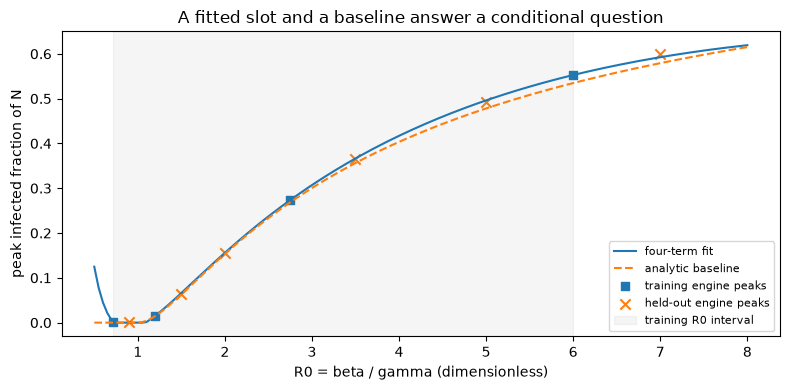

In [7]:
# Separate fitting points, held-out truths and both predictors in one coordinate system.
comparison_grid = np.linspace(0.5, 8.0, 151)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(comparison_grid, [train.predict(model, value) for value in comparison_grid], label="four-term fit")
ax.plot(comparison_grid, [peak_frac(value) for value in comparison_grid], "--", label="analytic baseline")
ax.scatter(train_r0, train_truth, marker="s", label="training engine peaks")
ax.scatter(held_r0, held_truth, marker="x", s=55, label="held-out engine peaks")
ax.axvspan(min(train_r0), max(train_r0), alpha=0.08, color="grey", label="training R0 interval")
ax.set_xlabel("R0 = beta / gamma (dimensionless)")
ax.set_ylabel("peak infected fraction of N")
ax.set_title("A fitted slot and a baseline answer a conditional question")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

The training squares sit close to the fitted line because those cases supplied its coefficients. Crosses represent different operating points, including one beyond the largest fitted ratio, and can deviate even though their schema is unchanged. The shaded region is only the observed training interval, not a confidence band. The baseline follows an analytic limiting relationship, so a small difference from the fitted curve can reflect initial-condition or numerical assumptions as well as approximation error. Neither curve reveals the time of the peak. Reading that time from this one-output model would invent information it does not return.

### Sensitivity: equal R0 can conceal incompatible initial conditions

Hold beta/gamma fixed and vary only the initial infections and reporting horizon. The engine still receives all those inputs, while `train.predict(model, r0)` sees none of them. The heatmap below includes an exactly unseeded control, a brief ten-day horizon and a substantial initially infected share. All are deliberately authored probes. They are not additional training samples or repeated estimates of observational uncertainty. Because the model has no initially immune argument either, changing that initial condition would also require an appropriately transformed model input and target definition.

same R0=2.75, same prediction=0.27345
engine peak fractions:
[[0.      0.01391 0.29235 0.3557 ]
 [0.      0.27345 0.29235 0.3557 ]
 [0.      0.27345 0.29235 0.3557 ]]


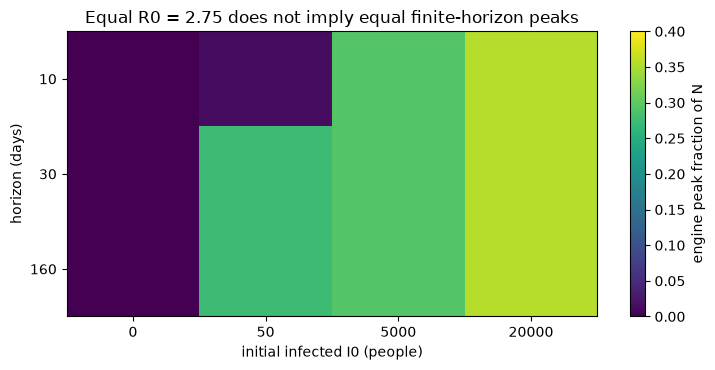

In [8]:
# The same scalar input cannot distinguish unseeded, short and heavily seeded outbreaks.
initial = [0, 50, 5000, 20000]
horizons = [10, 30, 160]
alias_truth = np.array([[infer.run(replace(base, I0=first, days=days)).peak_I / base.N
                         for first in initial] for days in horizons])
same_prediction = train.predict(model, base.beta / base.gamma)
print(f"same R0={base.beta/base.gamma:.2f}, same prediction={same_prediction:.5f}")
print("engine peak fractions:")
print(np.round(alias_truth, 5))
fig, ax = plt.subplots(figsize=(7.5, 3.8))
image = ax.imshow(alias_truth, aspect="auto", vmin=0, vmax=max(0.4, alias_truth.max()))
ax.set_xticks(range(len(initial)), initial)
ax.set_yticks(range(len(horizons)), horizons)
ax.set_xlabel("initial infected I0 (people)")
ax.set_ylabel("horizon (days)")
ax.set_title("Equal R0 = 2.75 does not imply equal finite-horizon peaks")
fig.colorbar(image, ax=ax, label="engine peak fraction of N")
fig.tight_layout()
plt.show()

The unseeded column stays at zero because the deterministic engine has no infection source. Seeded columns and different horizons produce other peak fractions, despite the single identical predictor value printed above the matrix. No coefficient optimization can give one scalar input several different correct outputs at once. This is loss of identifying information, not simply too little training or an insufficiently complex regression. The chosen output is a maximum over the requested finite horizon, so a short row can miss a future peak. The model cannot detect that distinction when horizon is omitted from its interface.

The reduced contract is useful only when the omitted quantities are fixed, negligible or explicitly outside the intended question. Initial immunity is not automatically encoded by calling a quantity R0: one must distinguish the disease's basic ratio from its effective ratio in a partially susceptible population. Similarly, changing both rates at fixed ratio preserves a limiting peak under ideal initial assumptions but can move that peak past a fixed horizon. The next figure asks a separate question about the fit's behavior outside the training interval, where even that restricted interpretation becomes fragile.

R0= 0.2, fit=1.00000, baseline=0.00000
R0= 1.0, fit=0.00000, baseline=0.00000
R0= 6.0, fit=0.55265, baseline=0.53471
R0=10.0, fit=0.64377, baseline=0.66974
R0=20.0, fit=0.46870, baseline=0.80021


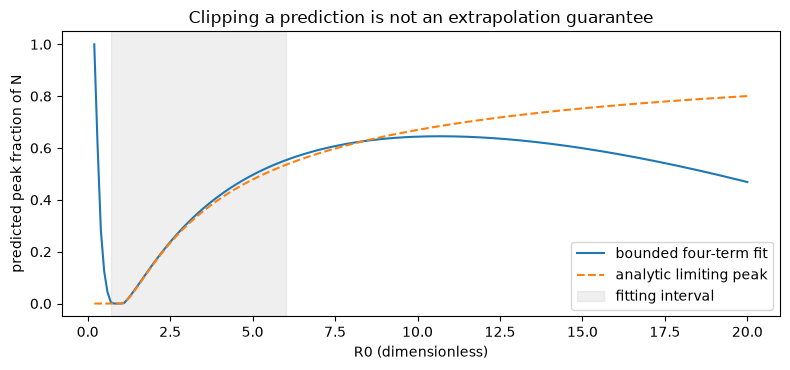

In [9]:
# Bound compliance can coexist with implausible extrapolation beyond the training range.
outside_grid = np.linspace(0.2, 20, 199)
outside_prediction = [train.predict(model, value) for value in outside_grid]
outside_baseline = [peak_frac(value) for value in outside_grid]
for value in (0.2, 1.0, 6.0, 10.0, 20.0):
    print(f"R0={value:4.1f}, fit={train.predict(model, value):.5f}, baseline={peak_frac(value):.5f}")
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(outside_grid, outside_prediction, label="bounded four-term fit")
ax.plot(outside_grid, outside_baseline, "--", label="analytic limiting peak")
ax.axvspan(min(train_r0), max(train_r0), alpha=0.12, color="grey", label="fitting interval")
ax.set_xlabel("R0 (dimensionless)")
ax.set_ylabel("predicted peak fraction of N")
ax.set_title("Clipping a prediction is not an extrapolation guarantee")
ax.legend()
fig.tight_layout()
plt.show()

The predictor remains in the legal output interval because its implementation clips the fitted expression. The resulting extrapolation can nevertheless flatten or turn downward outside the supported interval, whereas the limiting analytic peak rises with the reproduction ratio. This figure distinguishes numerical range compliance from scientific plausibility. Neither clipping nor a valid four-coefficient bundle supplies monotonicity, calibration or prediction intervals. Large-ratio outputs are educational stress probes, not new admitted operational cases; the CSV contract would flag sufficiently extreme ratios even when its elementary parameter ranges accept them.

### Use it on your own data

Prepare a CSV with case_id, beta, gamma, N, I0 and an explicit positive integer days field. Run preprocessing and inspect rejected reasons and flags before extracting features. Do not assume the optional horizon is strictly rejected: the current loader converts it, falls back on its default when conversion fails, and clamps nonpositive values. An importer should verify that this legacy behavior matches its intended time units. Split operating points before calling `train.run(training_params, external_models_dir)`; never fit on the observations later called held out. Keep the returned bundle or load it through `load_released`, then use `evaluate.run(bundle, holdout_params)` with independently reserved inputs.

The export stage consumes a case, accepted params, full inference result, seed, measured engine run_ms, admission flags, held-out metrics, model provenance and expectation bounds. It writes a compact trace and manifest under explicit derived/manifests directories. The trace's arrays are decimated and rounded for display, while its summary comes from the full engine result; recomputing the maximum of the trace can lose the true sampled peak. The manifest links case id, engine version, relative artifact path/byte count, parameters, lane decision, metrics and `models["surrogate-model"]`. This lesson explains that boundary without running the canonical orchestration or fabricating a runtime measurement.

Readiness further distinguishes a missing or invalid bundle, a released bundle answering during newer training, and a bake whose metrics still came from the baseline. Its state and provenance must accompany a prediction rather than being inferred from the presence of a file. The dormant API exposes the same document boundaries with explicit unavailable responses; a schema-declared GET route is not evidence of a live service. Extend the input contract and retrain only after defining the desired horizon and initial-condition population. A genuine epidemic application would additionally require appropriate observations, scientific validation and uncertainty treatment beyond this template example.

## Results

**Answer:** At R0 = 2.75 the fitted predictor returns 0.27345 for every initial-condition and horizon combination, including the exactly unseeded case whose engine peak is zero. The actual heatmap separates those outcomes, so R0 alone cannot identify every requested peak. The temporary fit uses four coefficients and is scored on six distinct held-out operating points; its printed RMSE and R squared describe only that explicitly authored population. They are different from the released twenty-point metrics and supply no clinical or forecasting qualification.

Prediction quality, contractual range and provenance answer different questions. A valid bundle can extrapolate implausibly; a fallback can implement the same interface while making different initial-state assumptions; an accurate finite-horizon fit can still omit a future peak. Preserving those distinctions is the practical value of the stage and model-slot design.

## Summary

- The real feature stage retains fields that the scalar surrogate discards.
- Training, prediction and evaluation use the existing public APIs, with temporary training isolated from released models.
- Disjoint held-out inputs expose interpolation limits but do not establish external validity.
- Identical R0 can correspond to different finite-horizon peaks when the initial state changes.
- Model shape, legal output range, model provenance and scientific adequacy require separate interpretations.

## References

- Kermack and McKendrick (1927), the governing SIR system: https://doi.org/10.1098/rspa.1927.0118
- Hethcote (2000), SIR assumptions and thresholds: https://doi.org/10.1137/S0036144500371907
- Miller (2012), final-size conditions and interpretation: https://doi.org/10.1007/s11538-012-9749-6
- NumPy primary least-squares API: https://numpy.org/doc/2.4/reference/generated/numpy.linalg.lstsq.html
- Actual fixed-basis trainer, not a claim that its basis is a research optimum: https://github.com/fsantibanezleal/CAOS_PRODUCT_TEMPLATE/blob/0190bf8/data-pipeline/pipeline/stages/train.py